## Export spike trains to CSV

This notebook validates the CON2PHYS npy source files and exports one CSV row per unit. It processes one mouse at a time to limit peak memory use.

Output columns:

- `mouse_id`: recording identifier
- `cluster_id`: unit identifier within a mouse
- `brain_area`: integer brain-area label (1–3)
- `recording_duration_sec`: recording duration derived from the LFP timestamp count at 500 Hz
- `unit_last_spike_sec`: final spike time for the unit
- `n_spikes`: number of spikes from the unit
- `spikes`: semicolon-separated spike times in seconds


In [1]:
import csv
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

## Parameters

In [2]:
project_folder = Path("E:/con2phys_submission")
source_folder = project_folder / "dataset_download" / "py-files"
output_folder = project_folder / "dataset"
csv_path = output_folder / "full_sua_dataset_refactored.csv"
metadata_csv_path = output_folder / "unit_metadata.csv"
figure_path = output_folder / "spikes_info_refactored.png"

LFP_SAMPLING_RATE_HZ = 500
EXPECTED_N_MICE = 18
EXPECTED_N_UNITS = 1_449
EXPECTED_N_SPIKES = 44_310_574
EXPECTED_BRAIN_AREAS = {1, 2, 3}
CSV_FIELDNAMES = [
    "mouse_id",
    "cluster_id",
    "brain_area",
    "recording_duration_sec",
    "unit_last_spike_sec",
    "n_spikes",
    "spikes",
]

### Loading and validation helpers

In [3]:
def discover_mouse_folders(source_folder: str | Path) -> list[Path]:
    """Return numeric mouse folders in deterministic numeric order."""
    source_folder = Path(source_folder)
    if not source_folder.is_dir():
        raise FileNotFoundError(f"Dataset folder not found: {source_folder}")

    mouse_folders = sorted(
        (path for path in source_folder.iterdir() if path.is_dir() and path.name.isdigit()),
        key=lambda path: int(path.name),
    )
    if len(mouse_folders) != EXPECTED_N_MICE:
        raise ValueError(
            f"Expected {EXPECTED_N_MICE} mouse folders, found {len(mouse_folders)}: "
            f"{[path.name for path in mouse_folders]}"
        )
    return mouse_folders


def recording_duration_from_lfp(mouse_folder: Path) -> float:
    """Derive duration from the common LFP timestamp count across all three areas."""
    timestamp_counts = []
    for brain_area in sorted(EXPECTED_BRAIN_AREAS):
        lfp_file = mouse_folder / f"lfp_{brain_area}.npy"
        lfp_shape = np.load(lfp_file, mmap_mode="r").shape
        if len(lfp_shape) != 2:
            raise ValueError(f"Expected a 2D LFP array in {lfp_file}, got {lfp_shape}")
        timestamp_counts.append(lfp_shape[1])

    if len(set(timestamp_counts)) != 1:
        raise ValueError(
            f"LFP timestamp counts differ for mouse {mouse_folder.name}: {timestamp_counts}"
        )
    return timestamp_counts[0] / LFP_SAMPLING_RATE_HZ


def load_and_validate_mouse(mouse_folder: Path) -> dict:
    """Load one mouse and validate spike, cluster, and brain-area alignment."""
    required_files = ["brain_area.npy", "clusters.npy", "spikes.npy"]
    missing_files = [name for name in required_files if not (mouse_folder / name).is_file()]
    if missing_files:
        raise FileNotFoundError(
            f"Mouse {mouse_folder.name} is missing required files: {missing_files}"
        )

    brain_area_data = np.load(
        mouse_folder / "brain_area.npy", allow_pickle=True
    ).item()
    if not isinstance(brain_area_data, dict):
        raise TypeError(f"brain_area.npy for mouse {mouse_folder.name} is not a dictionary")
    if set(brain_area_data) != {"cluster_id", "brain_area"}:
        raise ValueError(
            f"Unexpected brain_area.npy keys for mouse {mouse_folder.name}: "
            f"{sorted(brain_area_data)}"
        )

    unit_cluster_ids = np.asarray(brain_area_data["cluster_id"])
    unit_brain_areas = np.asarray(brain_area_data["brain_area"])
    spike_cluster_ids = np.load(mouse_folder / "clusters.npy", mmap_mode="r")
    spike_times = np.load(mouse_folder / "spikes.npy", mmap_mode="r")

    if unit_cluster_ids.ndim != 1 or unit_brain_areas.ndim != 1:
        raise ValueError(f"Unit metadata must be one-dimensional for mouse {mouse_folder.name}")
    if unit_cluster_ids.shape != unit_brain_areas.shape:
        raise ValueError(
            f"Unit cluster/area shapes differ for mouse {mouse_folder.name}: "
            f"{unit_cluster_ids.shape} vs {unit_brain_areas.shape}"
        )
    if spike_cluster_ids.ndim != 1 or spike_times.ndim != 1:
        raise ValueError(f"Spike arrays must be one-dimensional for mouse {mouse_folder.name}")
    if spike_cluster_ids.shape != spike_times.shape:
        raise ValueError(
            f"Cluster/spike shapes differ for mouse {mouse_folder.name}: "
            f"{spike_cluster_ids.shape} vs {spike_times.shape}"
        )
    if not np.isfinite(spike_times).all():
        raise ValueError(f"Non-finite spike times found for mouse {mouse_folder.name}")
    if spike_times.size and np.any(np.diff(spike_times) < 0):
        raise ValueError(f"Spike times are not sorted for mouse {mouse_folder.name}")
    if np.unique(unit_cluster_ids).size != unit_cluster_ids.size:
        raise ValueError(f"Duplicate unit cluster IDs found for mouse {mouse_folder.name}")

    observed_cluster_ids = np.unique(spike_cluster_ids)
    if not np.array_equal(np.sort(unit_cluster_ids), observed_cluster_ids):
        missing_labels = np.setdiff1d(observed_cluster_ids, unit_cluster_ids)
        units_without_spikes = np.setdiff1d(unit_cluster_ids, observed_cluster_ids)
        raise ValueError(
            f"Cluster metadata mismatch for mouse {mouse_folder.name}; "
            f"missing labels={missing_labels.tolist()}, "
            f"units without spikes={units_without_spikes.tolist()}"
        )

    brain_areas = {int(area) for area in unit_brain_areas}
    if not brain_areas <= EXPECTED_BRAIN_AREAS:
        raise ValueError(
            f"Unexpected brain-area values for mouse {mouse_folder.name}: {brain_areas}"
        )

    return {
        "mouse_id": int(mouse_folder.name),
        "spike_cluster_ids": spike_cluster_ids,
        "spike_times": spike_times,
        "brain_area_by_cluster": {
            int(cluster_id): int(brain_area)
            for cluster_id, brain_area in zip(unit_cluster_ids, unit_brain_areas)
        },
        "recording_duration_sec": recording_duration_from_lfp(mouse_folder),
    }

### Streaming CSV export

In [4]:
def export_spikes_to_csv(source_folder: str | Path, csv_path: str | Path) -> pd.DataFrame:
    """Validate and export one mouse at a time; return compact unit metadata."""
    source_folder = Path(source_folder)
    csv_path = Path(csv_path)
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    mouse_folders = discover_mouse_folders(source_folder)

    metadata_rows = []
    total_spikes = 0
    temporary_path = None

    try:
        with tempfile.NamedTemporaryFile(
            mode="w",
            encoding="utf-8",
            newline="",
            dir=csv_path.parent,
            prefix=f"{csv_path.stem}_",
            suffix=".tmp",
            delete=False,
        ) as csv_file:
            temporary_path = Path(csv_file.name)
            writer = csv.DictWriter(csv_file, fieldnames=CSV_FIELDNAMES)
            writer.writeheader()

            for mouse_folder in mouse_folders:
                mouse_data = load_and_validate_mouse(mouse_folder)
                cluster_ids = mouse_data["spike_cluster_ids"]
                spike_times = mouse_data["spike_times"]

                # A stable cluster sort groups units while preserving spike-time order.
                sort_order = np.argsort(cluster_ids, kind="stable")
                sorted_clusters = np.asarray(cluster_ids)[sort_order]
                sorted_spikes = np.asarray(spike_times)[sort_order]
                unique_clusters, starts, counts = np.unique(
                    sorted_clusters, return_index=True, return_counts=True
                )

                for cluster_id, start, count in zip(unique_clusters, starts, counts):
                    cluster_id = int(cluster_id)
                    unit_spikes = sorted_spikes[start : start + count]
                    unit_last_spike_sec = float(unit_spikes[-1])
                    metadata = {
                        "mouse_id": mouse_data["mouse_id"],
                        "cluster_id": cluster_id,
                        "brain_area": mouse_data["brain_area_by_cluster"][cluster_id],
                        "recording_duration_sec": mouse_data["recording_duration_sec"],
                        "unit_last_spike_sec": unit_last_spike_sec,
                        "n_spikes": int(count),
                    }
                    writer.writerow({
                        **metadata,
                        "spikes": ";".join(map(str, unit_spikes)),
                    })
                    metadata_rows.append(metadata)
                    total_spikes += int(count)

                print(
                    f"Mouse {mouse_data['mouse_id']:>2}: "
                    f"{len(unique_clusters):>3} units, {len(spike_times):>9,} spikes"
                )

        unit_metadata = pd.DataFrame(metadata_rows)
        if len(unit_metadata) != EXPECTED_N_UNITS:
            raise ValueError(
                f"Expected {EXPECTED_N_UNITS:,} units, exported {len(unit_metadata):,}"
            )
        if total_spikes != EXPECTED_N_SPIKES:
            raise ValueError(
                f"Expected {EXPECTED_N_SPIKES:,} spikes, exported {total_spikes:,}"
            )
        if unit_metadata[["mouse_id", "cluster_id"]].duplicated().any():
            raise ValueError("Duplicate (mouse_id, cluster_id) rows were generated")
        if set(unit_metadata["brain_area"]) != EXPECTED_BRAIN_AREAS:
            raise ValueError("The exported brain-area set is incomplete or invalid")

        temporary_path.replace(csv_path)
    except Exception:
        if temporary_path is not None:
            temporary_path.unlink(missing_ok=True)
        raise

    print(
        f"Created {csv_path} ({csv_path.stat().st_size / 1_000_000:.1f} MB)\n"
        f"Exported {len(unit_metadata):,} units and {total_spikes:,} spikes."
    )
    return unit_metadata


def save_unit_metadata(unit_metadata: pd.DataFrame, metadata_csv_path: str | Path) -> pd.DataFrame:
    """Save the compact metadata table atomically and verify the saved values."""
    metadata_csv_path = Path(metadata_csv_path)
    metadata_csv_path.parent.mkdir(parents=True, exist_ok=True)
    expected_columns = CSV_FIELDNAMES[:-1]
    if list(unit_metadata.columns) != expected_columns:
        raise ValueError(
            f"Unexpected metadata columns: {list(unit_metadata.columns)}; "
            f"expected {expected_columns}"
        )

    temporary_path = None
    try:
        with tempfile.NamedTemporaryFile(
            mode="w",
            encoding="utf-8",
            newline="",
            dir=metadata_csv_path.parent,
            prefix=f"{metadata_csv_path.stem}_",
            suffix=".tmp",
            delete=False,
        ) as metadata_file:
            temporary_path = Path(metadata_file.name)
            unit_metadata.to_csv(metadata_file, index=False)
        temporary_path.replace(metadata_csv_path)
    except Exception:
        if temporary_path is not None:
            temporary_path.unlink(missing_ok=True)
        raise

    saved_metadata = pd.read_csv(metadata_csv_path)
    pd.testing.assert_frame_equal(
        unit_metadata.reset_index(drop=True),
        saved_metadata,
        check_dtype=False,
        rtol=1e-12,
        atol=1e-12,
    )
    print(
        f"Created {metadata_csv_path} "
        f"({len(saved_metadata):,} rows, {metadata_csv_path.stat().st_size / 1_000:.1f} kB)."
    )
    return saved_metadata


unit_metadata = export_spikes_to_csv(source_folder, csv_path)
saved_unit_metadata = save_unit_metadata(unit_metadata, metadata_csv_path)

Mouse  1:  88 units, 2,525,186 spikes
Mouse  2:  79 units, 2,650,925 spikes
Mouse  3:  85 units, 2,274,429 spikes
Mouse  4:  57 units, 1,490,670 spikes
Mouse  5: 129 units, 4,504,339 spikes
Mouse  6:  67 units, 1,650,868 spikes
Mouse  7:  93 units, 3,094,437 spikes
Mouse  8:  90 units, 2,794,576 spikes
Mouse  9: 133 units, 4,267,460 spikes
Mouse 10:  41 units, 1,216,441 spikes
Mouse 11:  73 units, 1,243,467 spikes
Mouse 12:  42 units, 1,815,819 spikes
Mouse 13: 114 units, 2,342,528 spikes
Mouse 14:  44 units, 1,453,382 spikes
Mouse 15:  62 units, 1,802,174 spikes
Mouse 16: 100 units, 3,760,423 spikes
Mouse 17: 104 units, 3,761,706 spikes
Mouse 18:  48 units, 1,661,744 spikes
Created E:\con2phys_submission\dataset\full_sua_dataset_refactored.csv (801.6 MB)
Exported 1,449 units and 44,310,574 spikes.
Created E:\con2phys_submission\dataset\unit_metadata.csv (1,449 rows, 61.2 kB).


Mouse  4:  57 units, 1,490,670 spikes


Mouse  5: 129 units, 4,504,339 spikes


Mouse  6:  67 units, 1,650,868 spikes


Mouse  7:  93 units, 3,094,437 spikes


Mouse  8:  90 units, 2,794,576 spikes


... (7 outputs left out)

Mouse 16: 100 units, 3,760,423 spikes


Mouse 17: 104 units, 3,761,706 spikes


Mouse 18:  48 units, 1,661,744 spikes


Created E:\con2phys_submission\dataset\full_sua_dataset_refactored.csv (801.6 MB)
Exported 1,449 units and 44,310,574 spikes.
Created E:\con2phys_submission\dataset\unit_metadata.csv (1,449 rows, 61.2 kB).


### Validate the written CSV

In [5]:
def validate_spike_csv(csv_path: str | Path) -> dict:
    """Stream through the CSV and validate its schema and spike fields."""
    csv.field_size_limit(2**31 - 1)
    csv_path = Path(csv_path)
    row_count = 0
    spike_count = 0
    seen_units = set()

    with csv_path.open(newline="", encoding="utf-8") as csv_file:
        reader = csv.DictReader(csv_file)
        if reader.fieldnames != CSV_FIELDNAMES:
            raise ValueError(
                f"Unexpected CSV schema: {reader.fieldnames}; expected {CSV_FIELDNAMES}"
            )

        for row in reader:
            row_count += 1
            unit_key = (int(row["mouse_id"]), int(row["cluster_id"]))
            if unit_key in seen_units:
                raise ValueError(f"Duplicate unit row: {unit_key}")
            seen_units.add(unit_key)

            spikes = np.fromstring(row["spikes"], sep=";")
            expected_count = int(row["n_spikes"])
            if spikes.size != expected_count:
                raise ValueError(
                    f"Spike-count mismatch for {unit_key}: "
                    f"parsed {spikes.size}, expected {expected_count}"
                )
            if spikes.size == 0:
                raise ValueError(f"Empty spike train for {unit_key}")
            if not np.isfinite(spikes).all() or np.any(np.diff(spikes) < 0):
                raise ValueError(f"Invalid spike times for {unit_key}")
            if float(row["unit_last_spike_sec"]) != spikes[-1]:
                raise ValueError(f"Incorrect final spike time for {unit_key}")
            if float(row["recording_duration_sec"]) <= 0:
                raise ValueError(f"Invalid recording duration for {unit_key}")
            spike_count += spikes.size

    if row_count != EXPECTED_N_UNITS or spike_count != EXPECTED_N_SPIKES:
        raise ValueError(
            f"CSV totals do not match expectations: {row_count:,} units, "
            f"{spike_count:,} spikes"
        )

    return {"units": row_count, "spikes": spike_count}


csv_validation = validate_spike_csv(csv_path)
csv_validation

{'units': 1449, 'spikes': 44310574}

### Dataset summary plot

In [18]:
recording_duration_per_mouse

,mouse_id,recording_duration_sec,recording_duration_min
0,1,3350.972,55.849533
88,2,4655.478,77.591300
167,3,4102.642,68.377367
252,4,3934.196,65.569933
309,5,3897.864,64.964400
438,6,3544.798,59.079967
505,7,5812.326,96.872100
598,8,4640.534,77.342233
688,9,5109.246,85.154100
821,10,5103.534,85.058900


,brain_area,n_units,n_mice
0,1,649,18
1,2,478,18
2,3,322,18


,mouse_id,recording_duration_sec,recording_duration_min
count,18.000000,18.000000,18.000000
mean,9.500000,4441.133667,74.018894
std,5.338539,783.982365,13.066373
min,1.000000,3277.992000,54.633200
25%,5.250000,3934.393000,65.573217
50%,9.500000,4258.615000,70.976917
75%,13.750000,4998.977500,83.316292
max,18.000000,6046.362000,100.772700


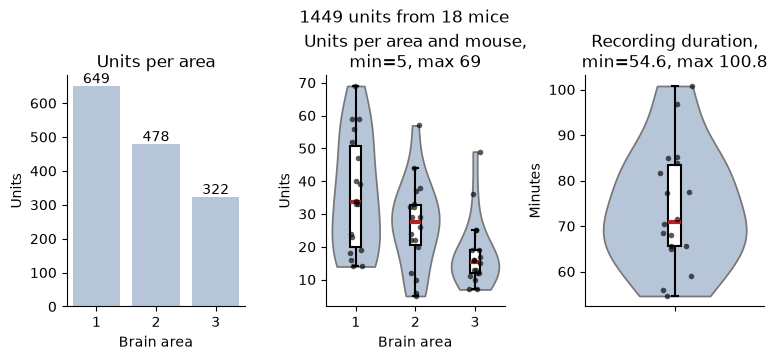

In [33]:
units_per_brain_area = (
    unit_metadata.groupby("brain_area")
    .agg(n_units=("cluster_id", "size"), n_mice=("mouse_id", "nunique"))
    .reset_index()
)
units_per_brain_area_per_mouse = (
    unit_metadata.groupby(["brain_area", "mouse_id"])
    .size()
    .reset_index(name="n_units")
)
recording_duration_per_mouse = (
    unit_metadata[["mouse_id", "recording_duration_sec"]]
    .drop_duplicates()
    .sort_values("mouse_id")
)
recording_duration_per_mouse["recording_duration_min"] = (
    recording_duration_per_mouse["recording_duration_sec"] / 60
)

display(units_per_brain_area)
display(recording_duration_per_mouse.describe())

color = "slategrey"
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
plt.subplots_adjust(wspace=0.45)

sns.barplot(
    ax=axes[0], x="brain_area", y="n_units",
    data=units_per_brain_area, color="lightsteelblue",
)
axes[0].bar_label(axes[0].containers[0], fmt="%.0f")
axes[0].set_title("Units per area")
axes[0].set_xlabel("Brain area")
axes[0].set_ylabel("Units")

sns.violinplot(
    ax=axes[1], x="brain_area", y="n_units",
    data=units_per_brain_area_per_mouse, cut=0, density_norm="width",
    color="lightsteelblue", inner=None,
)

sns.stripplot(
    ax=axes[1], x="brain_area", y="n_units",
    data=units_per_brain_area_per_mouse, color="black", s=4, alpha=0.65,
)
sns.boxplot(
    ax=axes[1], x="brain_area", y="n_units",
    data=units_per_brain_area_per_mouse, width=0.18, showfliers=False,
    boxprops={"facecolor": "white", "edgecolor": "black", "linewidth": 1.5},
    whiskerprops={"color": "black", "linewidth": 1.5},
    capprops={"color": "black", "linewidth": 1.5},
    medianprops={"color": "firebrick", "linewidth": 3},
)
axes[1].set_title(f"Units per area and mouse,\nmin={units_per_brain_area_per_mouse['n_units'].min()}, max {units_per_brain_area_per_mouse['n_units'].max()}")
axes[1].set_xlabel("Brain area")
axes[1].set_ylabel("Units")

sns.violinplot(
    ax=axes[2], y="recording_duration_min",
    data=recording_duration_per_mouse, cut=0, density_norm="width",
    color="lightsteelblue", inner=None,
)
sns.stripplot(
    ax=axes[2], y="recording_duration_min",
    data=recording_duration_per_mouse, color="black", s=4, alpha=0.65,
)
sns.boxplot(
    ax=axes[2], y="recording_duration_min",
    data=recording_duration_per_mouse, width=0.07, showfliers=False,
    boxprops={"facecolor": "white", "edgecolor": "black", "linewidth": 1.5},
    whiskerprops={"color": "black", "linewidth": 1.5},
    capprops={"color": "black", "linewidth": 1.5},
    medianprops={"color": "firebrick", "linewidth": 3},
)
axes[2].set_title(f"Recording duration,\nmin={recording_duration_per_mouse['recording_duration_min'].min():.1f}, max {recording_duration_per_mouse['recording_duration_min'].max():.1f}")
axes[2].set_xlabel("")
axes[2].set_ylabel("Minutes")

fig.suptitle(
    f"{len(unit_metadata)} units from {unit_metadata['mouse_id'].nunique()} mice",
    y=1.1,
)
sns.despine()
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)